# Policy Project: Advise the State Health Commissioner

## Setup and first look at the data

In [4]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

In [ ]:
# Read the data into the dataFrame for analysis
df = pd.read_csv('malaria_programme_data.csv')

# Checks the number of rows and columns
print(df.shape)

# Checking for empty cells
print(df.isna().sum().sum())

# Counting households in each LGA
print(df['lga'].value_counts())

# Checking how many households took part and how many did not?
print(df['programme'].value_counts())

# Checking how many households use a net and how many do not?
print(df['uses_net'].value_counts())

(600, 8)
0
lga
A    200
B    200
C    200
Name: count, dtype: int64
programme
No     305
Yes    295
Name: count, dtype: int64
uses_net
Yes    333
No     267
Name: count, dtype: int64


## Part A: Describe the data

### A1. Mean, median, variance, SD (sample formulas, n - 1) and the mode of clinic_visits

In [ ]:
# Grouping the four columns for statistical computations
cols = ['haemoglobin', 'clinic_visits', 'days_malaria_free', 'distance_km']
# Mean, Median, Variance and STD (diving by n-1, because the data is a sample)
summary = df[cols].agg(['mean', 'median', 'var', 'std'])

print(summary.round(3))

# Finding and returning the first value of the mode of clinic_visits
print('Mode of clinic_visits:', df['clinic_visits'].mode()[0])

        haemoglobin  clinic_visits  days_malaria_free  distance_km
mean         11.050          1.447            105.853        4.327
median       11.100          1.000             72.500        3.400
var           2.328          1.483          11197.154       19.345
std           1.526          1.218            105.817        4.398
Mode of clinic_visits: 1


#### Only haemoglobin has its mean close to the median and it is left skewed. The others have the mean greater than the median and are right skewed

### A2. Outliers in distance_km (1.5 x IQR rule)

In [10]:
d = df['distance_km']

# Q1 is the distance that 25% of households fall below
q1 = d.quantile(0.25)

# Q3: the distance that 75% of the households live closer than
q3 = d.quantile(0.75)

# Calculating the IGR
iqr = q3 - q1

# Lower fence (Anything below this fence is flagged a household too close)
lower_fence = q1 - 1.5 * iqr

# Anything above this fence is flagged as an unusually far household
upper_fence = q3 + 1.5 * iqr


print('Q1, Q3, IQR:', q1, q3, round(iqr, 2))

# Printing the fences
print('Fences:', round(lower_fence, 2), round(upper_fence, 2))

# Checking for outliers i.e distances below the lower fence and distance above the upper fence
outliers = df[(d < lower_fence) | (d > upper_fence)]

print('Number flagged:', len(outliers))


print(df.sort_values('distance_km', ascending=False).head(8)[['household_id', 'lga', 'programme', 'uses_net', 'distance_km']])

Q1, Q3, IQR: 2.2 5.1 2.9
Fences: -2.15 9.45
Number flagged: 28
     household_id lga programme uses_net  distance_km
34             35   A       Yes       No         55.0
190           191   A       Yes      Yes         47.0
216           217   B       Yes      Yes         42.5
192           193   A       Yes      Yes         38.0
116           117   A       Yes      Yes         29.2
285           286   B        No      Yes         19.0
61             62   A       Yes      Yes         16.0
60             61   A        No      Yes         15.3


C:\Users\user\AppData\Local\Temp\ipykernel_13060\4166625977.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['distance_km'], vert=False)


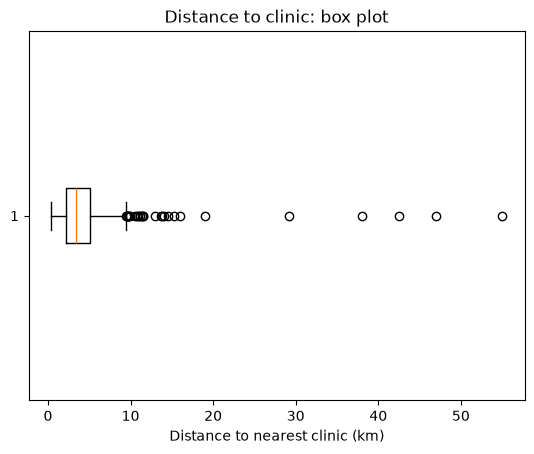

In [13]:
# Ploting distance to clinic on boxplot to show outliers
plt.boxplot(df['distance_km'], vert=False)
plt.xlabel('Distance to nearest clinic (km)')
plt.title('Distance to clinic: box plot')
plt.show()

In [14]:
# Removing household with distance from clinic greater than 30km
d_clean = d[d <= 30]
print('Households removed:', len(d) - len(d_clean))

# Showing the mean, median and skewness before and after removing the outliers
print('Before -> Mean:', round(d.mean(), 3), 'Median:', d.median(), 'Skewness:', round(d.skew(), 3))
print('After  -> Mean:', round(d_clean.mean(), 3), 'Median:', d_clean.median(), 'Skewness:', round(d_clean.skew(), 3))

Households removed: 4
Before -> Mean: 4.327 Median: 3.4 Skewness: 6.501
After  -> Mean: 4.05 Median: 3.4 Skewness: 2.575


##### I choose to remove the outliers because the are only four households that has significantly extremely distances that are beyond the others, thereby pushing the mean far away from the median. 

##### The remaining flagged 24 households that were above the upper fence are considerably remote household and not necessarily an outlier, so they are kept.

### A3. Skewness of days_malaria_free

In [15]:
days = df['days_malaria_free']
# Showing the skewness
print('Skewness:', round(days.skew(), 3))

# Checking the distance between the mean and Median to determine the symmetry
print('Mean:', round(days.mean(), 2), 'Median:', days.median())


Skewness: 2.011
Mean: 105.85 Median: 72.5


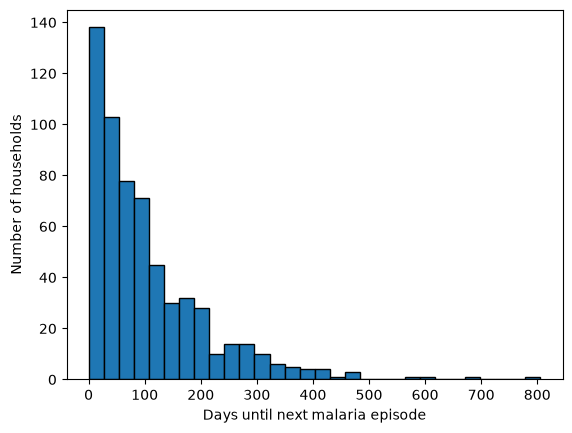

In [16]:
# Ploting a histogram to show skewness

plt.hist(days, bins=30, edgecolor='black')
plt.xlabel('Days until next malaria episode')
plt.ylabel('Number of households')
plt.show()

138 households have shorter waiting days (less than 30days)
Many households get their next episode soon.
A smaller number stay malaria-free for a long time.
A few stay free for very long, which pulls the mean (105.9 days) above the median (72.5 days).

### A4. Sample versus population

SAMPLE: A smaller, representative subset of the population that we actually collect data from, used to make inferences about the larger population for this project we have only 600 households from 3 LGA. This is a sample, and we aim to use the information derived from them to give the situation for the whole state.

POPULATION: The entire group of individuals, items, or events that we want to study and draw conclusions about for this project it the entire households in all the LGA of the state.

One reason why the sample might not give the accurate situation is: Only three LGAs was picked. The state has many more, and A, B and C may be different from the rest, for example in distance to clinics, income or how much malaria there is.

## Part B: Probability distributions

### B1. Binomial: at least 15 of 20 visited households use a net

In [17]:
p_net = (df['uses_net'] == 'Yes').mean()
print('Share of households using a net:', round(p_net, 3))
print('P(at least 15 of 20 use nets):', round(stats.binom.sf(14, n=20, p=p_net), 4))
print('Expected number of net users in 20 households:', round(20 * p_net, 1))

Share of households using a net: 0.555
P(at least 15 of 20 use nets): 0.0605
Expected number of net users in 20 households: 11.1


55.5% of households uses net.
The chance of finding 15 or more households using net out of 20 households is 6%

### B2. Poisson: clinic visits per household per month

In [18]:
lam = df['clinic_visits'].mean()
print('Mean:', round(lam, 3), 'Variance:', round(df['clinic_visits'].var(ddof=1), 3))
print('P(more than 3 visits):', round(stats.poisson.sf(3, mu=lam), 4))
print('P(no visits):', round(stats.poisson.pmf(0, mu=lam), 4))
print('Observed share with more than 3 visits:', round((df['clinic_visits'] > 3).mean(), 4))
print('Observed share with no visits:', round((df['clinic_visits'] == 0).mean(), 4))

Mean: 1.447 Variance: 1.483
P(more than 3 visits): 0.0591
P(no visits): 0.2354
Observed share with more than 3 visits: 0.055
Observed share with no visits: 0.2367


“Yes, because the mean (1.447) and variance (1.483) are close, and the model’s probabilities match what is observed.” And about 1 in 4 households makes no clinic visit in a month, and about 1 in 17 makes more than 3.

### B3. Exponential: days until the next malaria episode

In [19]:
mean_days = df['days_malaria_free'].mean()
print('Average days until next episode:', round(mean_days, 2))
print('P(malaria-free for more than 90 days):', round(stats.expon.sf(90, scale=mean_days), 4))
print('P(episode within 30 days):', round(stats.expon.cdf(30, scale=mean_days), 4))
print('Observed share malaria-free for more than 90 days:', round((df['days_malaria_free'] > 90).mean(), 4))
print('Observed share with an episode within 30 days:', round((df['days_malaria_free'] <= 30).mean(), 4))

Average days until next episode: 105.85
P(malaria-free for more than 90 days): 0.4273
P(episode within 30 days): 0.2468
Observed share malaria-free for more than 90 days: 0.4233
Observed share with an episode within 30 days: 0.2617


"""
Probability	
Malaria-free for more than 90 days	 Model = 42.7%.	Observed = 42.3%
Episode within 30 days	Model = 24.7%.	Observed = 26.2%

So about 43% of households stay malaria-free beyond 90 days, and about a quarter have an episode within a month. 
The exponential is a good model for this variable, which fits what we saw in A3: 
lots of short waits and a long tail of long ones.
"""

### B4. Shape of haemoglobin

Haemoglobin skewness: 0.029


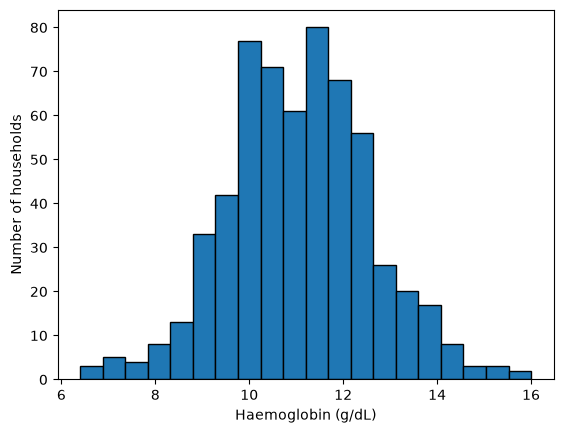

In [22]:
print('Haemoglobin skewness:', round(df['haemoglobin'].skew(), 3))
plt.hist(df['haemoglobin'], bins=20, edgecolor='black')
plt.xlabel('Haemoglobin (g/dL)')
plt.ylabel('Number of households')
plt.show()

A normal shape makes the p-values and confidence intervals more trustworthy.
a normal distribution is reasonable, because the skewness is near 0 (0.029) and the histogram is symmetric and bell-shaped.

## Part C: Tests and confidence intervals

### C1. One-sample z-test: is mean haemoglobin below the benchmark of 11.5 g/dL? (sigma = 1.5 known)

In [23]:
x = df['haemoglobin']
mu0 = 11.5
sigma = 1.5
n = len(x)
xbar = x.mean()
se = sigma / np.sqrt(n)
z = (xbar - mu0) / se
print('Sample mean:', round(xbar, 4), 'SE:', round(se, 4), 'z:', round(z, 3))
print('Left-tailed p:', stats.norm.cdf(z))
print('Right-tailed p:', stats.norm.sf(z))
print('Two-tailed p:', 2 * stats.norm.sf(abs(z)))
z_crit = stats.norm.ppf(0.975)
margin = z_crit * se
print('95% CI for the mean:', round(xbar - margin, 3), round(xbar + margin, 3))

Sample mean: 11.0502 SE: 0.0612 z: -7.346
Left-tailed p: 1.0230610691454319e-13
Right-tailed p: 0.9999999999998977
Two-tailed p: 2.0461221382908637e-13
95% CI for the mean: 10.93 11.17


**Fill in:**

- H0: μ = 11.5g/dL
- H1: μ < 11.5
- Tail chosen, and why (decide this from the question, before looking at the p-value): Left-tailed, because the question asked is: Is mean haemoglobin in the state below the benchmark?
- alpha: 0.05
- Test statistic: z = -7.346. The sample mean (11.0502) is more than seven standard errors below 11.5 (SE = 0.0612).
- p-value: 1.02e-13
- Decision: The p-value is far below 0.05, so reject H0
- One sentence of interpretation in plain language: The average haemoglobin in the sample (11.05 g/dL) is lower than the national benchmark of 11.5, and the 95% confidence interval (10.93 to 11.17) does not include 11.5, so haemoglobin in the state is likely below the benchmark.”

### C2. Two-sample t-test: do programme and non-programme households differ in haemoglobin?

In [24]:
yes = df.loc[df['programme'] == 'Yes', 'haemoglobin']
no = df.loc[df['programme'] == 'No', 'haemoglobin']
print('Programme: n =', len(yes), 'mean =', round(yes.mean(), 3), 'SD =', round(yes.std(ddof=1), 3))
print('Non-programme: n =', len(no), 'mean =', round(no.mean(), 3), 'SD =', round(no.std(ddof=1), 3))
res = stats.ttest_ind(yes, no, equal_var=False)
print('Welch two-tailed: t =', round(res.statistic, 3), 'p =', round(res.pvalue, 4), 'df =', round(res.df, 1))
res_right = stats.ttest_ind(yes, no, equal_var=False, alternative='greater')
print('Welch right-tailed: p =', round(res_right.pvalue, 4))
res_pooled = stats.ttest_ind(yes, no, equal_var=True)
print('Pooled (Student): t =', round(res_pooled.statistic, 3), 'p =', round(res_pooled.pvalue, 4))
diff = yes.mean() - no.mean()
ci = res.confidence_interval(confidence_level=0.95)
print('Difference in means:', round(diff, 3), '95% CI:', round(ci.low, 3), round(ci.high, 3))
cohen_d = diff / np.sqrt((yes.var(ddof=1) + no.var(ddof=1)) / 2)
print('Cohen d:', round(cohen_d, 3))

Programme: n = 295 mean = 11.176 SD = 1.499
Non-programme: n = 305 mean = 10.929 SD = 1.544
Welch two-tailed: t = 1.992 p = 0.0469 df = 598.0
Welch right-tailed: p = 0.0234
Pooled (Student): t = 1.991 p = 0.047
Difference in means: 0.247 95% CI: 0.003 0.491
Cohen d: 0.163


**Fill in:**

- H0: There is no difference: the mean haemoglobin of programme and non-programme households is equal (μ_programme = μ_non-programme).

- H1: The two means are different (μ_programme ≠ μ_non-programme).

- Tail chosen, and why (decide this from the question, before looking at the p-value): Two-tailed. The question says the groups “differ”, which allows a difference in either direction.

- alpha: 0.05

- Test statistic: t = 1.992 (Welch test, df = 598). The difference between the two group means is about two standard errors.

- p-value: The two-tailed Welch p-value, 0.0469. Don’t use the right-tailed 0.0234. It looks smaller, but it answers “is the programme mean higher?”, which isn’t the question.

- Decision: 0.0469 is just below 0.05, so reject H0. This is barely below the line.

- One sentence of interpretation in plain language: Programme households had a higher average haemoglobin level (11.176 g/dL, n = 295) than non-programme households (10.929 g/dL, n = 305), with a mean difference of 0.247 g/dL (95% CI: 0.003–0.491), which excludes zero and agrees with the statistical test, although the effect size was small (Cohen’s d = 0.163).

- Statistically significant? Large enough to matter in practice? 
Although the result is statistically significant (p = 0.047), its practical significance is doubtful because the effect size is small (Cohen’s d = 0.16), the average improvement is only about 0.25 g/dL against household variation of approximately 1.5, and the confidence interval suggests the true benefit could be negligible, raising the question of whether such a modest improvement justifies the cost of a state-wide programme.

### C3. Chi-square: is bed-net use related to the LGA?

In [25]:
tab = pd.crosstab(df['lga'], df['uses_net'])
print(tab)
chi2, p, dof, expected = stats.chi2_contingency(tab)
print('Chi-square:', round(chi2, 3), 'p-value:', round(p, 4), 'df:', dof)
print(pd.DataFrame(expected, index=tab.index, columns=tab.columns).round(1))
print('All expected counts >= 5:', (expected >= 5).all())
print(pd.crosstab(df['lga'], df['uses_net'], normalize='index').round(3))

uses_net   No  Yes
lga               
A          90  110
B          71  129
C         106   94
Chi-square: 12.43 p-value: 0.002 df: 2
uses_net    No    Yes
lga                  
A         89.0  111.0
B         89.0  111.0
C         89.0  111.0
All expected counts >= 5: True
uses_net     No    Yes
lga                   
A         0.450  0.550
B         0.355  0.645
C         0.530  0.470


**Fill in:**

- H0: Net use and LGA are independent, so there is no relationship between them.

- H1: Net use and LGA are related.

- Tail chosen, and why (decide this from the question, before looking at the p-value): A chi-square test of independence has no left or right tail to choose. It only measures how far the observed counts are from the expected ones, so a big value means a relationship

- alpha: 0.05

- Test statistic: Chi-square = 12.43, with df = 2. The df comes from (3 LGAs - 1) x (2 net categories - 1) = 2.

- p-value:0.002

- Decision: 0.002 is below 0.05, so reject H0.

- One sentence of interpretation in plain language: All expected counts are at least 5 (the printout says True), so the chi-square test is valid.

- Which LGA is the problem (use the row percentages)? 
LGA C is the problem. It’s the only LGA with less than half of households using nets, and it’s also below the overall average of 55.5%. In the counts, C has 94 net users where about 111 were expected, so it’s 17 short. B is the best, at 129 against 111 expected.

### C4. Chi-square: is bed-net use related to taking part in the programme?

In [26]:
tab2 = pd.crosstab(df['programme'], df['uses_net'])
print(tab2)
with_yates = stats.chi2_contingency(tab2, correction=True)
without_yates = stats.chi2_contingency(tab2, correction=False)
print('With continuity correction: chi-square =', round(with_yates[0], 3), 'p =', with_yates[1])
print('Without continuity correction: chi-square =', round(without_yates[0], 3), 'p =', without_yates[1])
print(pd.crosstab(df['programme'], df['uses_net'], normalize='index').round(3))

uses_net    No  Yes
programme          
No         178  127
Yes         89  206
With continuity correction: chi-square = 47.12 p = 6.675594654740575e-12
Without continuity correction: chi-square = 48.255 p = 3.742148714477899e-12
uses_net      No    Yes
programme              
No         0.584  0.416
Yes        0.302  0.698


**Fill in:**

- H0: Net use and taking part in the programme are independent. There is no relationship.

- H1: Net use and taking part in the programme are related.

- Tail chosen, and why (decide this from the question, before looking at the p-value): Not applicable. A chi-square test of independence measures how far the counts are from what’s expected, so it has no left or right tail.

- alpha: 0.05

- Test statistic: Chi-square = 47.12 with the correction, and 48.255 without it. Degrees of freedom = 1, because it’s a 2 x 2 table. State which one you use as your main result. Both are accepted, as long as you say which one.

- p-value: 6.68e-12 with the correction, and 3.74e-12 without. Both are far below 0.05.

- Decision: Reject H0, whichever version you use. The decision doesn’t change with or without the correction.

- One sentence of interpretation in plain language: Programme households are much more likely to use a net: about 70% against about 42%. The p-value says this gap is very unlikely to be chance.

- Does the decision change with or without the correction?
Programme households are far more likely to use a bed net (69.8% vs 41.6%), and this relationship is very unlikely to be due to chance, so the programme is linked to higher net use

### C5. 95% confidence interval for the share of households using nets (state target is 80%)

In [27]:
used = df['uses_net'] == 'Yes'
p_hat = used.mean()
n_hh = len(used)
se_p = np.sqrt(p_hat * (1 - p_hat) / n_hh)
z_crit = stats.norm.ppf(0.975)
low = p_hat - z_crit * se_p
high = p_hat + z_crit * se_p
print('Proportion:', round(p_hat, 4), '95% CI:', round(low, 4), round(high, 4))
print('Is 0.80 inside the interval?', low <= 0.80 <= high)

Proportion: 0.555 95% CI: 0.5152 0.5948
Is 0.80 inside the interval? False


Only 55.5% of households use bed nets (95% CI: 51.5%–59.5%), falling significantly short of the state's 80% target, which lies well outside the confidence interval and confirms that the shortfall is unlikely to be due to sampling chance. Coverage remains uneven across LGAs, with LGA C recording the lowest at 47%, while programme households have higher usage (70% vs. 42% among non-programme households), although even programme coverage remains below the 80% target.

### C6. Errors

**Pick ONE of your tests (not C4)** and explain in plain words what a Type I error and a Type II error would mean for the Commissioner in this situation.

I pick c2

H0 : says programme and non-programme households have the same average haemoglobin.

A Type I error:  would mean we conclude the programme improves haemoglobin when in truth it makes no difference. The Commissioner would scale up a programme that doesn’t work and waste state money that could be spent elsewhere.

A Type II error:  would mean we conclude the programme makes no difference when in truth it does help. The Commissioner might stop a programme that benefits families, and children and mothers would lose that benefit.